# Mini-Projeto: Modelagem e Solução de Problemas com Aprendizado por Reforço

**Alunos:** [Insira o nome dos integrantes do grupo aqui]

Neste notebook, vocês irão desenvolver o projeto prático da disciplina. O objetivo é aplicar os algoritmos tabulares clássicos em um ambiente de espaço contínuo (`MountainCar-v0`), utilizando técnicas de discretização, conforme o enunciado.

Deixe, neste colab, somente o código necessário para treinar os agentes com a parametrização mais vantajosa e gerar os gráficos, além do relatório em texto, na **análise dos resultados** e no **diário de bordo**. O restante da experimentação pode ser feito em outros colabs e ambientes. O diário de bordo deve comentar essa jornada e pode referenciar esses outros artefatos.

## 0. Configuração do ambiente e dos experimentos

A célula abaixo instala (se necessário) e importa as dependências. Funciona no Colab e localmente.

In [1]:
# ==============================================================================
# CONFIGURAÇÃO DO AMBIENTE: dependências e imports
# ==============================================================================
# Funciona tanto no Colab quanto localmente (Jupyter). Só instala o que estiver faltando.
import importlib.util
import subprocess
import sys

IN_COLAB = 'google.colab' in sys.modules

# nome do módulo -> pacote do pip
_DEPENDENCIAS = {
    'gymnasium': 'gymnasium[classic-control]',
    'pygame': 'pygame-ce',       # renderização do MountainCar (render_mode='rgb_array')
    'moviepy': 'moviepy',        # usado pelo wrapper RecordVideo para gravar .mp4
    'pandas': 'pandas',
    'matplotlib': 'matplotlib',
    'seaborn': 'seaborn',
}
_faltando = [pip for mod, pip in _DEPENDENCIAS.items() if importlib.util.find_spec(mod) is None]
if _faltando:
    print('Instalando dependências ausentes:', _faltando)
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *_faltando])

import base64
import glob
import hashlib
import itertools
import json
import os
import pickle
import random
import re
import time
import warnings

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from gymnasium.wrappers import RecordVideo
from IPython.display import HTML, display

try:  # scipy é opcional (usado só para o quantil da distribuição t)
    from scipy import stats as _scipy_stats
except ImportError:
    _scipy_stats = None

warnings.filterwarnings('ignore', category=UserWarning, module='gymnasium')

print(f'Python {sys.version.split()[0]} | gymnasium {gym.__version__} | numpy {np.__version__} | '
      f'pandas {pd.__version__} | seaborn {sns.__version__} | Colab: {IN_COLAB}')

Python 3.14.7 | gymnasium 1.4.0 | numpy 2.5.4 | pandas 3.1.0 | seaborn 0.13.2 | Colab: False


### CONFIG — escolhas experimentais

Todas as escolhas que definem o experimento (resoluções da discretização, hiperparâmetros de cada algoritmo, nº de seeds e de episódios) ficam **centralizadas na célula abaixo**. Os valores presentes são apenas *placeholders* para o código rodar.

- `MODO_TESTE_RAPIDO = True` roda uma versão minúscula (2 seeds, 5 episódios) só para checar que tudo executa — **não** usar esses números como resultado.
- Com `MODO_TESTE_RAPIDO = False`, *Run all* executa o experimento completo (≥ 10 seeds) e salva os resultados em disco; com `REUTILIZAR_RESULTADOS = True`, execuções posteriores apenas recarregam os resultados salvos.

In [2]:
# ==============================================================================
# CONFIG — ESCOLHAS EXPERIMENTAIS
# ==============================================================================
# Valores finais, escolhidos pela busca de hiperparâmetros feita fora deste notebook
# (pasta mini_projeto_busca/: busca.py, fase2.py, rodada2.py; plano e histórico em
# PLANO_EXPERIMENTOS.md). Critério de escolha: desempenho final = média de passos nos
# últimos 50 episódios (menor = melhor), média de 10 seeds. As justificativas estão nas
# células de texto das Tarefas A e B.

# --- Orçamento de execução ----------------------------------------------------------
# MODO_TESTE_RAPIDO = True roda uma versão minúscula (2 seeds, poucos episódios), só
# para verificar que todas as células rodam de ponta a ponta. NÃO use esses números
# como resultado. Para o experimento final, deixe False.
MODO_TESTE_RAPIDO = False

SEEDS = list(range(10))        # >= 10 seeds (exigência do enunciado)
N_EPISODIOS = 500              # nº de episódios de treino por execução (seed)
MAX_PASSOS_EPISODIO = 200      # limite padrão do MountainCar-v0 (wrapper TimeLimit)
MAX_PASSOS_TOTAL = None        # alternativa: orçamento total de passos no ambiente por
                               # execução (None = desativado; usa só N_EPISODIOS)

PASTA_RESULTADOS = 'resultados'  # onde ficam .pkl/.csv/figuras (no Colab: /content/...)
REUTILIZAR_RESULTADOS = True     # True: se a mesma configuração já foi rodada e salva,
                                 # carrega do disco em vez de treinar de novo.
                                 # (Se mudar o CÓDIGO dos agentes, apague a pasta ou use False.)

# --- Tarefa A: discretizações -------------------------------------------------------
# 'bins' = nº de intervalos por dimensão: (posição, velocidade).
# 'bordas' (opcional) = bordas internas de cada dimensão, para grades não uniformes.
DISCRETIZACOES = {
    # uniforme de alta resolução: 40 x 40 = 1.600 células
    'alta_resolucao': {'bins': (40, 40)},
    # uniforme de resolução média: 20 x 20 = 400 células (2ª melhor grade do Dyna-Q)
    'media_resolucao': {'bins': (20, 20)},
    # não uniforme: posição em 6 intervalos uniformes; velocidade em 16 intervalos,
    # mais finos perto de 0 (0,002) e mais largos nos extremos (até 0,02): 96 células
    'vel_detalhada': {'bins': (6, 16), 'bordas': [
        [-0.9, -0.6, -0.3, 0.0, 0.3],
        [-0.05, -0.035, -0.02, -0.012, -0.007, -0.004, -0.002, 0.0,
         0.002, 0.004, 0.007, 0.012, 0.02, 0.035, 0.05]]},
    # não uniforme nas duas dimensões: posição em 18 intervalos (0,05 perto da parede da
    # esquerda, do fundo do vale e do objetivo; até 0,2 no meio) e a velocidade da
    # vel_detalhada: 18 x 16 = 288 células
    'pos_vel_detalhada': {'bins': (18, 16), 'bordas': [
        [-1.15, -1.1, -1.0, -0.85, -0.7, -0.6, -0.55, -0.5, -0.45, -0.4,
         -0.25, -0.05, 0.15, 0.3, 0.4, 0.45, 0.5],
        [-0.05, -0.035, -0.02, -0.012, -0.007, -0.004, -0.002, 0.0,
         0.002, 0.004, 0.007, 0.012, 0.02, 0.035, 0.05]]},
}

# --- Tarefa B: hiperparâmetros por discretização e algoritmo -------------------------
# Parâmetros comuns:
#   alpha              taxa de aprendizado
#   gamma              fator de desconto
#   epsilon_inicial    epsilon no 1º episódio
#   epsilon_final      piso do epsilon
#   decaimento_epsilon fator multiplicativo por episódio (tipo_decaimento='exponencial')
#   tipo_decaimento    'exponencial' ou 'linear' (linear usa episodios_decaimento)
#   q_inicial          valor inicial de todos os Q(s,a)
# Específicos:
#   SARSA(λ): lambda_, tipo_traco ('acumulativo' | 'substituicao'), limiar_traco
#   Dyna-Q:   n_planejamento (N), tipo_modelo ('ultimo' | 'amostral')
_COMUNS = dict(alpha=0.1, gamma=1.0, epsilon_inicial=0.5, epsilon_final=0.01,
               decaimento_epsilon=0.99, tipo_decaimento='exponencial', q_inicial=0.0)

HIPERPARAMETROS = {
    nome_disc: {
        'Q-learning': dict(_COMUNS),
        'SARSA(λ)':   dict(_COMUNS, lambda_=0.9, tipo_traco='acumulativo'),
        'Dyna-Q':     dict(_COMUNS, n_planejamento=40, tipo_modelo='amostral'),
    }
    for nome_disc in DISCRETIZACOES
}
# Na média resolução e na pos_vel_detalhada, o Dyna-Q usa a melhor configuração encontrada
# para cada uma dessas grades
HIPERPARAMETROS['media_resolucao']['Dyna-Q'].update(q_inicial=-300.0, n_planejamento=20)
HIPERPARAMETROS['pos_vel_detalhada']['Dyna-Q'].update(q_inicial=-300.0, n_planejamento=20)

if MODO_TESTE_RAPIDO:
    # Orçamento minúsculo, pasta separada para não misturar com os resultados reais.
    SEEDS = [0, 1]
    N_EPISODIOS = 5
    MAX_PASSOS_TOTAL = None
    PASTA_RESULTADOS = 'resultados_teste_rapido'
    REUTILIZAR_RESULTADOS = False
    print('*** MODO_TESTE_RAPIDO ativo: os números gerados NÃO são resultados válidos. ***')

os.makedirs(PASTA_RESULTADOS, exist_ok=True)
print(f'{len(SEEDS)} seeds | {N_EPISODIOS} episódios/execução | '
      f'discretizações: {list(DISCRETIZACOES)} | resultados em "{PASTA_RESULTADOS}/"')


10 seeds | 500 episódios/execução | discretizações: ['alta_resolucao', 'media_resolucao', 'vel_detalhada', 'pos_vel_detalhada'] | resultados em "resultados/"


## Tarefa A: Modelagem do Espaço de Estados (Discretização)

Implementem abaixo **duas formas ou resoluções de discretização diferentes**

In [3]:
# ==============================================================================
# TAREFA A: FUNÇÕES DE DISCRETIZAÇÃO
# ==============================================================================
# O estado do MountainCar-v0 é contínuo: obs = (posição, velocidade), com
#   posição   em [-1.2, 0.6]   (o objetivo é atingir posição >= 0.5)
#   velocidade em [-0.07, 0.07]
# Para usar métodos tabulares, mapeamos cada obs para UMA célula de uma grade
# retangular e, em seguida, para um único índice inteiro s em {0, ..., n_estados-1}.


class DiscretizadorGrade:
    """Discretizador por grade retangular, parametrizado pela resolução.

    Modo uniforme (padrão): cada dimensão d é dividida em `bins[d]` intervalos de mesma
    largura entre low[d] e high[d].
    Modo com bordas explícitas (opcional): `bordas[d]` é a lista das bordas INTERNAS da
    dimensão d (len = bins[d] - 1), permitindo grades não uniformes (ex.: mais finas
    perto do topo da montanha). Útil se quiser comparar "formas" e não só resoluções.

    O índice tabular é o índice linear (row-major) da célula:
        s = i_posicao * bins[1] + i_velocidade
    Valores fora de [low, high] são "grudados" na primeira/última célula.
    """

    def __init__(self, bins, low, high, bordas=None, nome=None):
        self.bins = tuple(int(b) for b in bins)
        self.low = np.asarray(low, dtype=float)
        self.high = np.asarray(high, dtype=float)
        assert len(self.bins) == len(self.low) == len(self.high), 'dimensões inconsistentes'
        self.nome = nome or 'x'.join(map(str, self.bins))
        self.n_dims = len(self.bins)
        self.n_estados = int(np.prod(self.bins))

        if bordas is None:
            self.bordas = None
            # escala por dimensão: (x - low) * escala -> posição contínua em "células"
            self._escala = [b / (h - l) for b, l, h in zip(self.bins, self.low, self.high)]
        else:
            self.bordas = [np.asarray(e, dtype=float) for e in bordas]
            for d, e in enumerate(self.bordas):
                assert len(e) == self.bins[d] - 1, f'bordas[{d}] deve ter bins[{d}]-1 valores'
                assert np.all(np.diff(e) > 0), f'bordas[{d}] deve ser estritamente crescente'

        # cópias em listas Python (acesso escalar mais rápido no laço de treino)
        self._low_l = [float(v) for v in self.low]
        # multiplicadores para o índice linear (row-major)
        self._mult = [int(np.prod(self.bins[d + 1:])) for d in range(self.n_dims)]

    def indices(self, obs):
        """Retorna a tupla (i_0, ..., i_{D-1}) da célula que contém `obs`."""
        idx = []
        for d in range(self.n_dims):
            x = float(obs[d])
            if self.bordas is None:
                i = int((x - self._low_l[d]) * self._escala[d])
            else:
                i = int(np.searchsorted(self.bordas[d], x, side='right'))
            idx.append(min(max(i, 0), self.bins[d] - 1))  # recorta para [0, bins-1]
        return tuple(idx)

    def __call__(self, obs):
        """Mapeia uma observação contínua para o índice tabular (int)."""
        return int(sum(i * m for i, m in zip(self.indices(obs), self._mult)))

    def indices_de_estado(self, s):
        """Inverso do índice linear: s -> (i_0, ..., i_{D-1})."""
        return tuple(int(i) for i in np.unravel_index(int(s), self.bins))

    def bordas_dimensao(self, d):
        """Todas as bordas (inclusive low/high) da dimensão d — útil para gráficos."""
        if self.bordas is None:
            return np.linspace(self.low[d], self.high[d], self.bins[d] + 1)
        return np.concatenate([[self.low[d]], self.bordas[d], [self.high[d]]])

    def centro(self, s):
        """Centro (no espaço contínuo) da célula do estado discreto s."""
        idx = self.indices_de_estado(s)
        return np.array([(self.bordas_dimensao(d)[i] + self.bordas_dimensao(d)[i + 1]) / 2
                         for d, i in enumerate(idx)])

    def descricao(self):
        larguras = [np.diff(self.bordas_dimensao(d)) for d in range(self.n_dims)]
        txt = ', '.join(f'dim{d}: {self.bins[d]} bins (largura {w.min():.4g}'
                        + (f'..{w.max():.4g}' if not np.allclose(w, w[0]) else '') + ')'
                        for d, w in enumerate(larguras))
        return f'[{self.nome}] {self.n_estados} estados discretos | {txt}'

    def __repr__(self):
        return f'DiscretizadorGrade(nome={self.nome!r}, bins={self.bins})'


def criar_discretizador(bins, nome=None, bordas=None, env_id='MountainCar-v0'):
    """Cria um discretizador usando os limites do espaço de observação do ambiente."""
    env = gym.make(env_id)
    low, high = env.observation_space.low, env.observation_space.high
    env.close()
    return DiscretizadorGrade(bins, low, high, bordas=bordas, nome=nome)


# Instancia as discretizações definidas na célula CONFIG
DISCRETIZADORES = {nome: criar_discretizador(cfg['bins'], nome=nome, bordas=cfg.get('bordas'))
                   for nome, cfg in DISCRETIZACOES.items()}

for _disc in DISCRETIZADORES.values():
    print(_disc.descricao())

# Verificação rápida: estado inicial típico (posição ~ -0.5, velocidade 0) e extremos
for _disc in DISCRETIZADORES.values():
    exemplos = [(-0.5, 0.0), (-1.2, -0.07), (0.6, 0.07)]
    print(_disc.nome, {ex: (_disc.indices(ex), _disc(ex)) for ex in exemplos})

[alta_resolucao] 1600 estados discretos | dim0: 40 bins (largura 0.045), dim1: 40 bins (largura 0.0035)
[media_resolucao] 400 estados discretos | dim0: 20 bins (largura 0.09), dim1: 20 bins (largura 0.007)
[vel_detalhada] 96 estados discretos | dim0: 6 bins (largura 0.3), dim1: 16 bins (largura 0.002..0.02)
[pos_vel_detalhada] 288 estados discretos | dim0: 18 bins (largura 0.05..0.2), dim1: 16 bins (largura 0.002..0.02)
alta_resolucao {(-0.5, 0.0): ((15, 20), 620), (-1.2, -0.07): ((0, 0), 0), (0.6, 0.07): ((39, 39), 1599)}
media_resolucao {(-0.5, 0.0): ((7, 10), 150), (-1.2, -0.07): ((0, 0), 0), (0.6, 0.07): ((19, 19), 399)}


vel_detalhada {(-0.5, 0.0): ((2, 8), 40), (-1.2, -0.07): ((0, 0), 0), (0.6, 0.07): ((5, 15), 95)}
pos_vel_detalhada {(-0.5, 0.0): ((8, 8), 136), (-1.2, -0.07): ((0, 0), 0), (0.6, 0.07): ((17, 15), 287)}


**Justificativa das discretizações escolhidas (resoluções/formas):**

_(A ser escrito pelo aluno)_

## Tarefa B: Implementação dos Agentes Tabulares
Implementem os algoritmos solicitados.

In [4]:
# ==============================================================================
# TAREFA B: AGENTES
# ==============================================================================
# Os três agentes compartilham a mesma interface, usada pelo executor da Tarefa C:
#
#     a = agente.iniciar_episodio(s)                 # escolhe a 1ª ação do episódio
#     enquanto o episódio não acabar:
#         s', r, terminou, truncou = env.step(a)     # (s, s' já discretizados)
#         a = agente.passo(s, a, r, s', terminou, truncou)   # aprende e devolve a próxima ação
#         s = s'
#     agente.finalizar_episodio()                    # decai o epsilon
#
# Tratamento do fim de episódio:
#   * terminou=True  -> estado terminal verdadeiro (carro chegou ao topo): alvo = r.
#   * truncou=True   -> corte por limite de tempo (TimeLimit, 200 passos): s' NÃO é terminal,
#                       então ainda fazemos bootstrap a partir de s' (o episódio só é interrompido).
#
# CONTAGEM DE ATUALIZAÇÕES DE VALOR-Q (self.n_atualizacoes) — regra usada:
#   cada vez que a regra de atualização é aplicada a UMA entrada Q(s,a), conta-se 1
#   (mesmo que o valor numérico não mude, ex.: erro TD = 0).
#   * Q-learning: 1 atualização por passo no ambiente.
#   * SARSA(λ):   por passo, conta-se o nº de pares (s,a) com traço de elegibilidade != 0
#                 (todos eles recebem Q(s,a) += α·δ·e(s,a)).
#   * Dyna-Q:     1 atualização real + N atualizações de planejamento por passo no ambiente
#                 (N = n_planejamento; sempre exatamente N, pois o planejamento amostra pares
#                 já observados e, após o 1º passo real, sempre existe ao menos um).


class AgenteTabularBase:
    """Base comum: tabela Q, política epsilon-greedy e decaimento de epsilon."""

    nome = 'base'

    def __init__(self, n_estados, n_acoes, alpha=0.1, gamma=1.0,
                 epsilon_inicial=1.0, epsilon_final=0.01, decaimento_epsilon=0.99,
                 tipo_decaimento='exponencial', episodios_decaimento=None,
                 q_inicial=0.0, seed=None):
        self.n_estados, self.n_acoes = n_estados, n_acoes
        self.alpha, self.gamma = alpha, gamma
        self.epsilon_inicial, self.epsilon_final = epsilon_inicial, epsilon_final
        self.decaimento_epsilon = decaimento_epsilon
        assert tipo_decaimento in ('exponencial', 'linear')
        if tipo_decaimento == 'linear':
            assert episodios_decaimento, "tipo_decaimento='linear' exige episodios_decaimento"
        self.tipo_decaimento, self.episodios_decaimento = tipo_decaimento, episodios_decaimento
        self.epsilon = epsilon_inicial
        self.q_values = np.full((n_estados, n_acoes), float(q_inicial))
        self.rng = np.random.default_rng(seed)   # toda a aleatoriedade do agente vem daqui
        self.n_atualizacoes = 0                  # contador de atualizações de Q (ver regra acima)
        self.episodios_concluidos = 0

    # ---------------- política ----------------
    def Q(self, s, a):
        return self.q_values[s, a]

    def V(self, s):
        return self.q_values[s].max()

    def greedy_action(self, s):
        """argmax_a Q(s,a) com desempate aleatório (importante com Q inicial constante)."""
        q = self.q_values[s]
        melhores = np.flatnonzero(q == q.max())
        if len(melhores) == 1:
            return int(melhores[0])
        return int(self.rng.choice(melhores))

    def act(self, s):
        """Ação epsilon-greedy."""
        if self.rng.random() < self.epsilon:
            return int(self.rng.integers(self.n_acoes))
        return self.greedy_action(s)

    # ---------------- ciclo do episódio ----------------
    def iniciar_episodio(self, s):
        return self.act(s)

    def passo(self, s, a, r, s2, terminou, truncou):
        raise NotImplementedError

    def finalizar_episodio(self):
        self.episodios_concluidos += 1
        self.atualizar_epsilon()

    def atualizar_epsilon(self):
        """Decaimento por episódio: exponencial (eps *= fator) ou linear até episodios_decaimento."""
        if self.tipo_decaimento == 'exponencial':
            self.epsilon = max(self.epsilon_final, self.epsilon * self.decaimento_epsilon)
        else:
            frac = min(1.0, self.episodios_concluidos / self.episodios_decaimento)
            self.epsilon = self.epsilon_inicial + frac * (self.epsilon_final - self.epsilon_inicial)

    # ---------------- utilidades ----------------
    def _atualizar_q_learning(self, s, a, r, s2, terminou):
        """Uma atualização de Q-learning em Q(s,a) (usada pelo baseline e pelo Dyna-Q)."""
        alvo = r if terminou else r + self.gamma * self.q_values[s2].max()
        self.q_values[s, a] += self.alpha * (alvo - self.q_values[s, a])
        self.n_atualizacoes += 1


# ------------------------------------------------------------------------------
# 1) Baseline: Q-learning (TD de 1 passo, off-policy)
# ------------------------------------------------------------------------------
class AgenteQLearning(AgenteTabularBase):
    """Q(s,a) <- Q(s,a) + α [r + γ max_a' Q(s',a') - Q(s,a)].
    Obs.: SARSA(0) equivale ao AgenteSarsaLambda com lambda_=0."""

    nome = 'Q-learning'

    def passo(self, s, a, r, s2, terminou, truncou):
        self._atualizar_q_learning(s, a, r, s2, terminou)
        if terminou or truncou:
            return None
        return self.act(s2)


# ------------------------------------------------------------------------------
# 2) SARSA(λ) com traços de elegibilidade (visão "backward")
# ------------------------------------------------------------------------------
class AgenteSarsaLambda(AgenteTabularBase):
    """SARSA(λ) tabular com traços de elegibilidade e(s,a).

    A cada passo:
        a' ~ epsilon-greedy(s')                       (se s' não for terminal)
        δ  = r + γ Q(s',a') - Q(s,a)                  (δ = r - Q(s,a) se terminal)
        e(s,a) += 1   (tipo_traco='acumulativo')   ou   e(s,a) = 1   ('substituicao')
        para todo (x,b) com e(x,b) != 0:  Q(x,b) += α δ e(x,b)
        e <- γ λ e
    Os traços são zerados no início de cada episódio.

    limiar_traco: se > 0, traços com valor < limiar são zerados (truncamento). Isso
    reduz o nº de pares atualizados (e portanto a contagem de atualizações). Com 0.0,
    o algoritmo é o exato (os traços só decaem geometricamente).
    """

    nome = 'SARSA(λ)'

    def __init__(self, n_estados, n_acoes, lambda_=0.9, tipo_traco='substituicao',
                 limiar_traco=0.0, **kwargs):
        super().__init__(n_estados, n_acoes, **kwargs)
        assert tipo_traco in ('acumulativo', 'substituicao')
        self.lambda_, self.tipo_traco, self.limiar_traco = lambda_, tipo_traco, limiar_traco
        self.E = np.zeros_like(self.q_values)   # traços de elegibilidade
        self._E_flat = self.E.reshape(-1)       # visões 1-D (mesma memória)
        self._Q_flat = self.q_values.reshape(-1)

    def iniciar_episodio(self, s):
        self.E.fill(0.0)
        return self.act(s)

    def passo(self, s, a, r, s2, terminou, truncou):
        # próxima ação (on-policy). Em truncamento ainda precisamos de a' para o bootstrap.
        a2 = None if terminou else self.act(s2)
        alvo = r if terminou else r + self.gamma * self.q_values[s2, a2]
        delta = alvo - self.q_values[s, a]

        if self.tipo_traco == 'acumulativo':
            self.E[s, a] += 1.0
        else:
            self.E[s, a] = 1.0

        ativos = np.flatnonzero(self._E_flat)            # pares com traço != 0
        self._Q_flat[ativos] += self.alpha * delta * self._E_flat[ativos]
        self.n_atualizacoes += len(ativos)               # cada par ativo = 1 atualização

        self._E_flat[ativos] *= self.gamma * self.lambda_
        if self.limiar_traco > 0:
            pequenos = ativos[self._E_flat[ativos] < self.limiar_traco]
            self._E_flat[pequenos] = 0.0

        if terminou or truncou:
            return None
        return a2


# ------------------------------------------------------------------------------
# 3) Dyna-Q: Q-learning + modelo aprendido + N passos de planejamento
# ------------------------------------------------------------------------------
class AgenteDynaQ(AgenteTabularBase):
    """Dyna-Q tabular (Sutton & Barto, seção 8.2).

    A cada passo real: (d) atualização Q-learning com a transição real;
                       (e) atualização do modelo Model(s,a);
                       (f) N atualizações de planejamento com transições simuladas:
                           (s,a) ~ uniforme entre pares já observados,
                           (r,s',terminou) ~ Model(s,a), atualização Q-learning.

    ALIASING DE ESTADOS: o ambiente é determinístico no espaço CONTÍNUO, mas, após a
    discretização, o mesmo par discreto (s,a) agrupa muitos estados contínuos diferentes
    e pode levar a próximos estados discretos s' diferentes (e até a terminal/não terminal).
    Ou seja, o modelo no espaço discreto deixa de ser determinístico. É preciso escolher
    o que o modelo guarda/devolve — parâmetro `tipo_modelo`:
        'ultimo'   -> guarda só a ÚLTIMA transição vista para (s,a) (Dyna-Q "clássico",
                      que supõe ambiente determinístico);
        'amostral' -> guarda as contagens de todos os desfechos (r, s', terminou) vistos para
                      (s,a) e amostra proporcionalmente a elas (modelo de máxima verossimilhança).
    Independentemente do tipo, as contagens são sempre registradas, para que
    `estatisticas_modelo()` possa medir o quanto o modelo é "não determinístico".

    Obs.: truncamento por tempo (TimeLimit) NÃO é dinâmica do ambiente, então o modelo
    guarda apenas `terminou` (chegada ao objetivo), nunca `truncou`.
    """

    nome = 'Dyna-Q'

    def __init__(self, n_estados, n_acoes, n_planejamento=10, tipo_modelo='ultimo',
                 seed=None, **kwargs):
        super().__init__(n_estados, n_acoes, seed=seed, **kwargs)
        assert tipo_modelo in ('ultimo', 'amostral')
        self.n_planejamento, self.tipo_modelo = int(n_planejamento), tipo_modelo
        # modelo[(s,a)] = {'ultimo': desfecho, 'desfechos': [...], 'contagens': [...], 'indice': {desfecho: i}}
        # desfecho = (r, s', terminou)
        self.modelo = {}
        self.pares_observados = []                     # lista de (s,a) já vistos (para amostrar)
        self._rng_plan = random.Random(seed)           # RNG (rápido) só para o planejamento
        self.n_atualizacoes_reais = 0
        self.n_atualizacoes_planejamento = 0

    def _atualizar_modelo(self, s, a, r, s2, terminou):
        chave = (s, a)
        desfecho = (float(r), int(s2), bool(terminou))
        reg = self.modelo.get(chave)
        if reg is None:
            reg = {'ultimo': None, 'desfechos': [], 'contagens': [], 'indice': {}}
            self.modelo[chave] = reg
            self.pares_observados.append(chave)
        i = reg['indice'].get(desfecho)
        if i is None:
            reg['indice'][desfecho] = len(reg['desfechos'])
            reg['desfechos'].append(desfecho)
            reg['contagens'].append(1)
        else:
            reg['contagens'][i] += 1
        reg['ultimo'] = desfecho

    def _amostrar_desfecho(self, reg):
        if self.tipo_modelo == 'ultimo' or len(reg['desfechos']) == 1:
            return reg['ultimo'] if self.tipo_modelo == 'ultimo' else reg['desfechos'][0]
        return self._rng_plan.choices(reg['desfechos'], weights=reg['contagens'])[0]

    def planejar(self, n):
        rng, pares = self._rng_plan, self.pares_observados
        for _ in range(n):
            sp, ap = pares[rng.randrange(len(pares))]
            rp, s2p, tp = self._amostrar_desfecho(self.modelo[(sp, ap)])
            self._atualizar_q_learning(sp, ap, rp, s2p, tp)
        self.n_atualizacoes_planejamento += n

    def passo(self, s, a, r, s2, terminou, truncou):
        self._atualizar_q_learning(s, a, r, s2, terminou)   # (d) aprendizado direto
        self.n_atualizacoes_reais += 1
        self._atualizar_modelo(s, a, r, s2, terminou)       # (e) aprendizado do modelo
        if self.n_planejamento > 0:                          # (f) planejamento
            self.planejar(self.n_planejamento)
        if terminou or truncou:
            return None
        return self.act(s2)

    def estatisticas_modelo(self):
        """Medidas descritivas do modelo aprendido (apoio à análise de aliasing, item 4.2c)."""
        if not self.modelo:
            return {}
        n_desf, entropias, visitas = [], [], []
        n_auto, n_trans, n_misto_terminal = 0, 0, 0
        for (s, a), reg in self.modelo.items():
            c = np.asarray(reg['contagens'], dtype=float)
            p = c / c.sum()
            n_desf.append(len(c))
            entropias.append(float(-(p * np.log2(p)).sum()))
            visitas.append(c.sum())
            n_trans += c.sum()
            n_auto += sum(ci for (r_, s2_, t_), ci in zip(reg['desfechos'], c) if s2_ == s)
            if len({t_ for (_, _, t_) in reg['desfechos']}) > 1:
                n_misto_terminal += 1
        n_desf, entropias, visitas = map(np.asarray, (n_desf, entropias, visitas))
        return {
            'pares_observados': len(self.modelo),
            'frac_tabela_observada': len(self.modelo) / (self.n_estados * self.n_acoes),
            'transicoes_registradas': int(n_trans),
            'frac_pares_nao_deterministicos': float((n_desf > 1).mean()),
            'media_desfechos_distintos_por_par': float(n_desf.mean()),
            'max_desfechos_distintos_por_par': int(n_desf.max()),
            'entropia_media_bits': float(entropias.mean()),
            'entropia_media_ponderada_bits': float((entropias * visitas).sum() / visitas.sum()),
            'frac_transicoes_para_mesmo_estado': float(n_auto / n_trans),
            'pares_terminal_ambiguo': int(n_misto_terminal),
        }


# Mapeamento nome -> classe (os nomes precisam bater com as chaves de HIPERPARAMETROS)
ALGORITMOS = {
    'Q-learning': AgenteQLearning,
    'SARSA(λ)': AgenteSarsaLambda,
    'Dyna-Q': AgenteDynaQ,
}
print('Agentes disponíveis:', list(ALGORITMOS))

Agentes disponíveis: ['Q-learning', 'SARSA(λ)', 'Dyna-Q']


**Justificativa dos hiperparâmetros escolhidos para cada algoritmo e discretização:**

_(A ser escrito pelo aluno)_

## Tarefa C: Avaliação Experimental e Reprodutibilidade
Treine cada algoritmo pelo menos 10 vezes com sementes diferentes (seeds) para lidar com a alta variância do Aprendizado por Reforço.

In [5]:
# ==============================================================================
# TAREFA C: funções do executor de experimentos (treino, várias seeds, busca, resumo)
# ==============================================================================

def criar_ambiente(max_passos_episodio=200, render_mode=None):
    """MountainCar-v0 com limite de passos por episódio (TimeLimit)."""
    return gym.make('MountainCar-v0', max_episode_steps=max_passos_episodio, render_mode=render_mode)


def _obter_discretizador(discretizador):
    """Aceita o nome (chave de DISCRETIZADORES) ou o próprio objeto DiscretizadorGrade."""
    return DISCRETIZADORES[discretizador] if isinstance(discretizador, str) else discretizador


def executar_treinamento(classe_agente, discretizador, params, seed, n_episodios=None,
                         max_passos_total=None, max_passos_episodio=200):
    """Treina UM agente com UMA seed e devolve (DataFrame por episódio, agente treinado).

    Critério de parada: `n_episodios` episódios e/ou `max_passos_total` passos no ambiente
    (o que vier primeiro; o episódio em andamento é sempre concluído).

    Colunas registradas por episódio:
        episodio, recompensa, passos (= passos até o sucesso; = max_passos_episodio se falhou),
        sucesso, passos_acumulados (passos no ambiente desde o início do treino),
        atualizacoes_q_episodio, atualizacoes_q_acumuladas, epsilon (usado no episódio), tempo_s.
    """
    assert n_episodios is not None or max_passos_total is not None, 'defina um critério de parada'
    discretizador = _obter_discretizador(discretizador)

    # --- Reprodutibilidade: todas as fontes de aleatoriedade recebem a seed ---
    random.seed(seed)
    np.random.seed(seed)
    env = criar_ambiente(max_passos_episodio)
    env.action_space.seed(seed)
    agente = classe_agente(n_estados=discretizador.n_estados, n_acoes=env.action_space.n,
                           seed=seed, **params)
    obs, _ = env.reset(seed=seed)   # semeia o RNG do ambiente; os resets seguintes continuam a sequência

    registros, passos_acum, ep = [], 0, 0
    t0 = time.perf_counter()
    while True:
        if n_episodios is not None and ep >= n_episodios:
            break
        if max_passos_total is not None and passos_acum >= max_passos_total:
            break
        if ep > 0:
            obs, _ = env.reset()
        s = discretizador(obs)
        a = agente.iniciar_episodio(s)
        epsilon_ep = agente.epsilon
        atualiz_ini = agente.n_atualizacoes
        recompensa, passos, terminou, truncou = 0.0, 0, False, False
        while not (terminou or truncou):
            obs, r, terminou, truncou, _ = env.step(a)
            s2 = discretizador(obs)
            a = agente.passo(s, a, r, s2, terminou, truncou)
            s = s2
            recompensa += r
            passos += 1
        agente.finalizar_episodio()
        ep += 1
        passos_acum += passos
        registros.append({
            'episodio': ep,
            'recompensa': recompensa,
            'passos': passos,
            'sucesso': bool(terminou),
            'passos_acumulados': passos_acum,
            'atualizacoes_q_episodio': agente.n_atualizacoes - atualiz_ini,
            'atualizacoes_q_acumuladas': agente.n_atualizacoes,
            'epsilon': epsilon_ep,
            'tempo_s': time.perf_counter() - t0,
        })
    env.close()
    return pd.DataFrame(registros), agente


def _slug(txt):
    txt = str(txt).replace('λ', 'lambda')
    return re.sub(r'[^A-Za-z0-9_.-]+', '_', txt).strip('_')


def _chave_config(nome_algoritmo, discretizador, params, seeds, n_episodios,
                  max_passos_total, max_passos_episodio):
    """Hash da configuração completa — identifica o arquivo de resultados salvo."""
    cfg = {
        'algoritmo': nome_algoritmo,
        'bins': discretizador.bins,
        'bordas': None if discretizador.bordas is None else [list(map(float, e)) for e in discretizador.bordas],
        'params': params, 'seeds': list(seeds), 'n_episodios': n_episodios,
        'max_passos_total': max_passos_total, 'max_passos_episodio': max_passos_episodio,
    }
    return hashlib.md5(json.dumps(cfg, sort_keys=True, default=str).encode()).hexdigest()[:10], cfg


def executar_varias_seeds(nome_algoritmo, discretizacao, params, seeds=None, n_episodios=None,
                          max_passos_total='config', max_passos_episodio=None, pasta=None,
                          reutilizar=None, rotulo=None, verbose=True):
    """Roda `executar_treinamento` para cada seed e salva tudo em disco (.pkl + .csv).

    Argumentos None/'config' usam os valores da célula CONFIG (lidos no momento da chamada).
    Devolve um "pacote" (dict) com:
        'df'       DataFrame com todos os episódios de todas as seeds (+ colunas algoritmo,
                   discretizacao, seed, rotulo)
        'q_tables' {seed: tabela Q final}   (permite gravar vídeos sem re-treinar)
        'extras'   {seed: estatísticas do modelo (Dyna-Q) ou {}}
        'config', 'arquivo'
    Se `reutilizar` e o arquivo da mesma configuração existir, apenas carrega do disco.
    """
    seeds = SEEDS if seeds is None else seeds
    n_episodios = N_EPISODIOS if n_episodios is None else n_episodios
    max_passos_total = MAX_PASSOS_TOTAL if max_passos_total == 'config' else max_passos_total
    max_passos_episodio = MAX_PASSOS_EPISODIO if max_passos_episodio is None else max_passos_episodio
    pasta = PASTA_RESULTADOS if pasta is None else pasta
    reutilizar = REUTILIZAR_RESULTADOS if reutilizar is None else reutilizar

    disc = _obter_discretizador(discretizacao)
    nome_disc = discretizacao if isinstance(discretizacao, str) else disc.nome
    classe = ALGORITMOS[nome_algoritmo]
    chave, cfg = _chave_config(nome_algoritmo, disc, params, seeds, n_episodios,
                               max_passos_total, max_passos_episodio)
    os.makedirs(pasta, exist_ok=True)
    base = os.path.join(pasta, f'{_slug(nome_disc)}__{_slug(nome_algoritmo)}__{chave}')

    if reutilizar and os.path.exists(base + '.pkl'):
        with open(base + '.pkl', 'rb') as f:
            pacote = pickle.load(f)
        if verbose:
            print(f'[carregado] {nome_disc} | {nome_algoritmo} | {rotulo or ""} <- {base}.pkl')
        pacote['df']['rotulo'] = rotulo if rotulo is not None else nome_algoritmo
        return pacote

    dfs, q_tables, extras = [], {}, {}
    t0 = time.perf_counter()
    for seed in seeds:
        df, agente = executar_treinamento(classe, disc, params, seed, n_episodios=n_episodios,
                                          max_passos_total=max_passos_total,
                                          max_passos_episodio=max_passos_episodio)
        df.insert(0, 'seed', seed)
        dfs.append(df)
        q_tables[seed] = agente.q_values.copy()
        extras[seed] = agente.estatisticas_modelo() if hasattr(agente, 'estatisticas_modelo') else {}
        if verbose:
            ult = df.tail(min(50, len(df)))
            print(f'  {nome_disc} | {nome_algoritmo} | seed {seed}: {len(df)} ep., '
                  f'{df.passos_acumulados.iloc[-1]} passos, {df.atualizacoes_q_acumuladas.iloc[-1]} atualiz. Q, '
                  f'passos médios (últ. {len(ult)} ep.) {ult.passos.mean():.1f} '
                  f'[{time.perf_counter() - t0:.0f}s]')
    df_total = pd.concat(dfs, ignore_index=True)
    df_total.insert(0, 'discretizacao', nome_disc)
    df_total.insert(0, 'algoritmo', nome_algoritmo)
    df_total['rotulo'] = rotulo if rotulo is not None else nome_algoritmo

    pacote = {'df': df_total, 'q_tables': q_tables, 'extras': extras, 'config': cfg,
              'arquivo': base + '.pkl'}
    with open(base + '.pkl', 'wb') as f:
        pickle.dump(pacote, f)
    df_total.to_csv(base + '.csv', index=False)
    return pacote


# ------------------------------------------------------------------------------
# Estatística: média e intervalo de confiança de 95% entre seeds
# ------------------------------------------------------------------------------
# quantis t_{0.975, gl} (usados se o scipy não estiver instalado)
_T975 = {1: 12.706, 2: 4.303, 3: 3.182, 4: 2.776, 5: 2.571, 6: 2.447, 7: 2.365, 8: 2.306,
         9: 2.262, 10: 2.228, 11: 2.201, 12: 2.179, 13: 2.160, 14: 2.145, 15: 2.131,
         16: 2.120, 17: 2.110, 18: 2.101, 19: 2.093, 20: 2.086, 25: 2.060, 30: 2.042,
         40: 2.021, 60: 2.000, 120: 1.980}


def quantil_t(gl, conf=0.95):
    if _scipy_stats is not None:
        return float(_scipy_stats.t.ppf(0.5 + conf / 2, gl))
    assert abs(conf - 0.95) < 1e-9, 'sem scipy, apenas conf=0.95 é suportado'
    chaves = sorted(_T975)
    return _T975[max([k for k in chaves if k <= gl], default=1)] if gl <= 120 else 1.960


def media_ic(valores, conf=0.95):
    """(média, meia-largura do IC) usando a distribuição t de Student (n-1 graus de liberdade)."""
    v = np.asarray(valores, dtype=float)
    v = v[~np.isnan(v)]
    n = len(v)
    if n == 0:
        return np.nan, np.nan
    if n == 1:
        return float(v[0]), np.nan
    return float(v.mean()), float(quantil_t(n - 1, conf) * v.std(ddof=1) / np.sqrt(n))


def metricas_por_execucao(df, ultimos=50):
    """Métricas-resumo de cada execução (uma linha por seed e configuração)."""
    def _m(g):
        u = g.tail(min(ultimos, len(g)))
        return pd.Series({
            'episodios': len(g),
            'passos_medios_todos': g.passos.mean(),          # área sob a curva / nº episódios
            f'passos_medios_ult{ultimos}': u.passos.mean(),
            f'taxa_sucesso_ult{ultimos}': u.sucesso.mean(),
            'primeiro_sucesso_ep': g.episodio[g.sucesso].min() if g.sucesso.any() else np.nan,
            'passos_ambiente_total': g.passos_acumulados.iloc[-1],
            'atualizacoes_q_total': g.atualizacoes_q_acumuladas.iloc[-1],
            'atualiz_q_por_passo': g.atualizacoes_q_acumuladas.iloc[-1] / g.passos_acumulados.iloc[-1],
            'tempo_s': g.tempo_s.iloc[-1],
        })
    chaves = [c for c in ('discretizacao', 'algoritmo', 'rotulo', 'seed') if c in df.columns]
    return df.groupby(chaves, sort=False).apply(_m, include_groups=False).reset_index()


def tabela_resumo(df, ultimos=50, por=('discretizacao', 'algoritmo', 'rotulo'), conf=0.95):
    """Média ± meia-largura do IC 95% (t) entre seeds, para cada configuração."""
    met = metricas_por_execucao(df, ultimos)
    por = [c for c in por if c in met.columns]
    colunas = [c for c in met.columns if c not in por + ['seed']]
    linhas = []
    for chave, g in met.groupby(por, sort=False):
        linha = dict(zip(por, chave if isinstance(chave, tuple) else (chave,)))
        linha['n_seeds'] = g.seed.nunique()
        for c in colunas:
            m, h = media_ic(g[c], conf)
            linha[c] = m
            if c != 'episodios':
                linha[c + '_ic95'] = h
        linhas.append(linha)
    return pd.DataFrame(linhas)


# ------------------------------------------------------------------------------
# Busca de hiperparâmetros (para o aluno conduzir a sua própria busca)
# ------------------------------------------------------------------------------
def gerar_grade(base, **listas):
    """Produto cartesiano: gerar_grade({'alpha':0.1,...}, n_planejamento=[5,10], alpha=[0.1,0.3])
    -> lista de dicts (cópias de `base` com cada combinação aplicada)."""
    nomes = list(listas)
    return [dict(base, **dict(zip(nomes, combo))) for combo in itertools.product(*listas.values())]


def busca_hiperparametros(nome_algoritmo, discretizacao, lista_params, seeds=None,
                          n_episodios=None, ultimos=50, pasta=None, ordenar_por=None, verbose=False):
    """Roda `executar_varias_seeds` para cada dict de `lista_params` e devolve
    (tabela-resumo com uma linha por configuração, DataFrame com todos os episódios).

    Cada configuração é salva/cacheada em disco como no experimento principal, então
    a busca pode ser interrompida e retomada. A coluna 'rotulo' identifica a configuração
    (apenas os parâmetros que variam na lista) e pode ser usada como `hue` nos gráficos.
    """
    nome_disc = discretizacao if isinstance(discretizacao, str) else _obter_discretizador(discretizacao).nome
    variaveis = sorted({k for p in lista_params for k in p
                        if len({json.dumps(q.get(k), default=str) for q in lista_params}) > 1})
    dfs = []
    for i, params in enumerate(lista_params):
        rotulo = ', '.join(f'{k}={params.get(k)}' for k in variaveis) or f'config{i}'
        t0 = time.perf_counter()
        pacote = executar_varias_seeds(nome_algoritmo, discretizacao, params, seeds=seeds,
                                       n_episodios=n_episodios, pasta=pasta, rotulo=rotulo,
                                       verbose=verbose)
        print(f'[{i + 1}/{len(lista_params)}] {nome_disc} | {nome_algoritmo} | {rotulo} '
              f'({time.perf_counter() - t0:.0f}s)')
        dfs.append(pacote['df'])
    todos = pd.concat(dfs, ignore_index=True)
    resumo = tabela_resumo(todos, ultimos=ultimos)
    params_df = pd.DataFrame([{**{k: p.get(k) for k in variaveis}} for p in lista_params])
    resumo = pd.concat([resumo.reset_index(drop=True), params_df], axis=1)
    if ordenar_por is not None:
        resumo = resumo.sort_values(ordenar_por).reset_index(drop=True)
    pasta = PASTA_RESULTADOS if pasta is None else pasta
    resumo.to_csv(os.path.join(pasta, f'busca__{_slug(nome_disc)}__{_slug(nome_algoritmo)}.csv'), index=False)
    return resumo, todos

In [6]:
# ==============================================================================
# TAREFA C: Execução dos experimentos
# ==============================================================================
# Para cada discretização e cada algoritmo, treina com todas as SEEDS usando os
# hiperparâmetros da célula CONFIG. Os resultados ficam salvos em PASTA_RESULTADOS
# (um .pkl + .csv por configuração) e são reaproveitados se REUTILIZAR_RESULTADOS=True,
# então os gráficos podem ser refeitos sem re-treinar.
# Tempo: depende do nº de episódios, da resolução e de N (Dyna-Q); o progresso é impresso por seed.

PACOTES = {}   # (discretização, algoritmo) -> pacote (df, q_tables, extras, config)
for nome_disc in DISCRETIZACOES:
    for nome_alg in ALGORITMOS:
        PACOTES[(nome_disc, nome_alg)] = executar_varias_seeds(
            nome_alg, nome_disc, HIPERPARAMETROS[nome_disc][nome_alg])

resultados = pd.concat([p['df'] for p in PACOTES.values()], ignore_index=True)
resultados.to_csv(os.path.join(PASTA_RESULTADOS, 'resultados_todos.csv'), index=False)
print(f'\n{len(resultados)} episódios registrados -> {PASTA_RESULTADOS}/resultados_todos.csv')
resultados.head()

[carregado] alta_resolucao | Q-learning |  <- resultados\alta_resolucao__Q-learning__e0ae7c2143.pkl


[carregado] alta_resolucao | SARSA(λ) |  <- resultados\alta_resolucao__SARSA_lambda__f2fdf41a3d.pkl
[carregado] alta_resolucao | Dyna-Q |  <- resultados\alta_resolucao__Dyna-Q__38652fa4c2.pkl
[carregado] media_resolucao | Q-learning |  <- resultados\media_resolucao__Q-learning__4f6f2e158a.pkl
[carregado] media_resolucao | SARSA(λ) |  <- resultados\media_resolucao__SARSA_lambda__22c21fc868.pkl
[carregado] media_resolucao | Dyna-Q |  <- resultados\media_resolucao__Dyna-Q__4cd01a4fd8.pkl
[carregado] vel_detalhada | Q-learning |  <- resultados\vel_detalhada__Q-learning__2a433330d2.pkl
[carregado] vel_detalhada | SARSA(λ) |  <- resultados\vel_detalhada__SARSA_lambda__c3af96c76c.pkl
[carregado] vel_detalhada | Dyna-Q |  <- resultados\vel_detalhada__Dyna-Q__5ea80b42d1.pkl
[carregado] pos_vel_detalhada | Q-learning |  <- resultados\pos_vel_detalhada__Q-learning__51be2061ba.pkl
[carregado] pos_vel_detalhada | SARSA(λ) |  <- resultados\pos_vel_detalhada__SARSA_lambda__d156d5bc4c.pkl
[carregado]


60000 episódios registrados -> resultados/resultados_todos.csv


,algoritmo,discretizacao,seed,episodio,recompensa,passos,sucesso,passos_acumulados,atualizacoes_q_episodio,atualizacoes_q_acumuladas,epsilon,tempo_s,rotulo
0,Q-learning,alta_resolucao,0,1,-200.0,200,False,200,200,200,0.500000,0.010164,Q-learning
1,Q-learning,alta_resolucao,0,2,-200.0,200,False,400,200,400,0.495000,0.019552,Q-learning
2,Q-learning,alta_resolucao,0,3,-200.0,200,False,600,200,600,0.490050,0.029010,Q-learning
3,Q-learning,alta_resolucao,0,4,-200.0,200,False,800,200,800,0.485149,0.040520,Q-learning
4,Q-learning,alta_resolucao,0,5,-200.0,200,False,1000,200,1000,0.480298,0.055626,Q-learning


## 4.1 Gráficos de Curva de Aprendizado

Com os dados coletados, gerem os dois conjuntos de gráficos exigidos. Utilizem o `seaborn.lineplot`, pois ele calcula e desenha o Intervalo de Confiança de 95% automaticamente ao receber dados de múltiplas repetições (seeds).

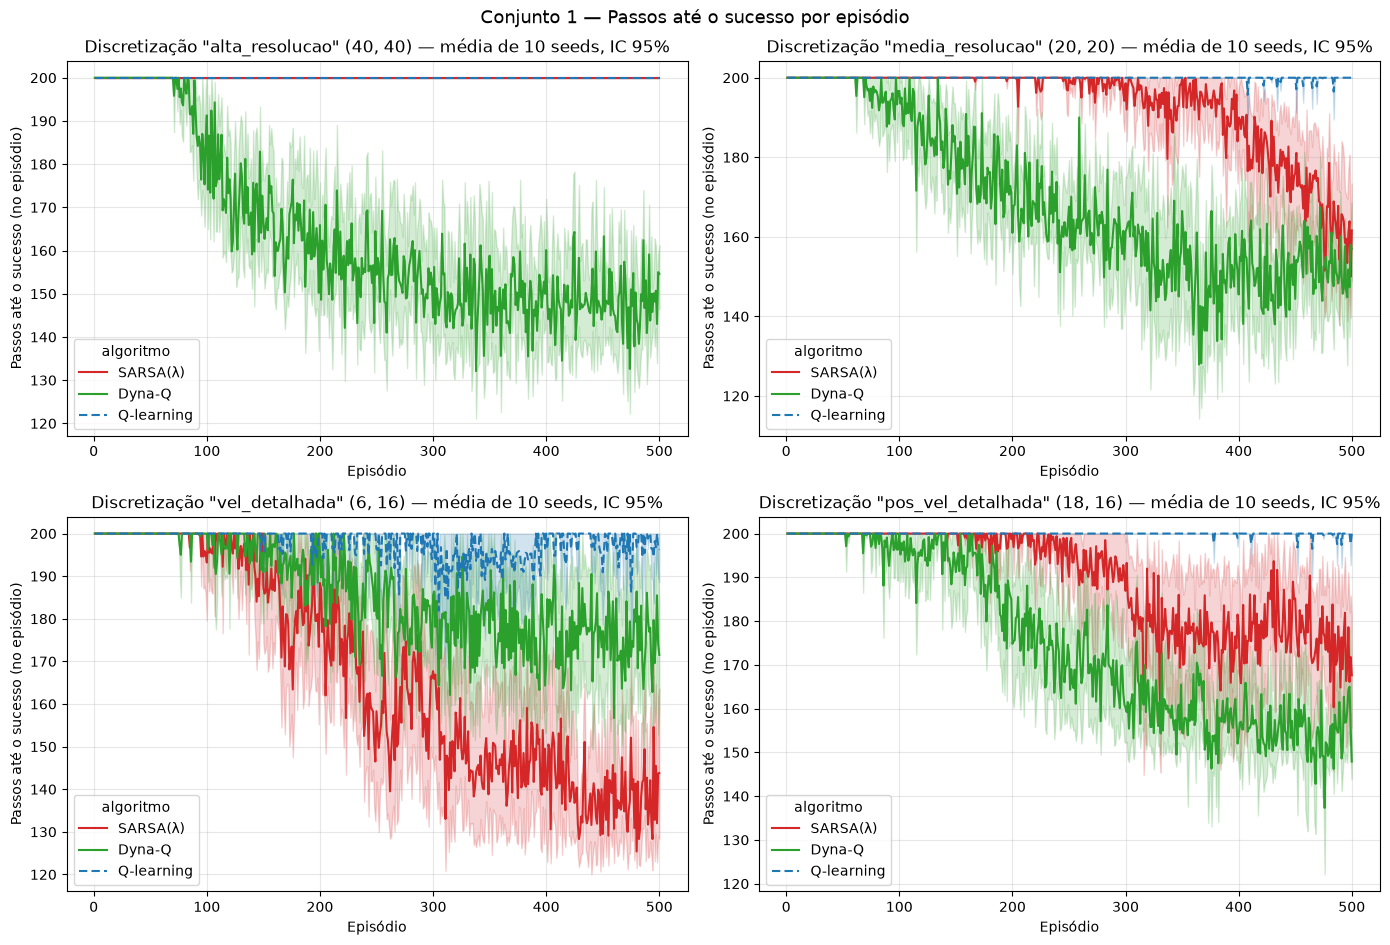

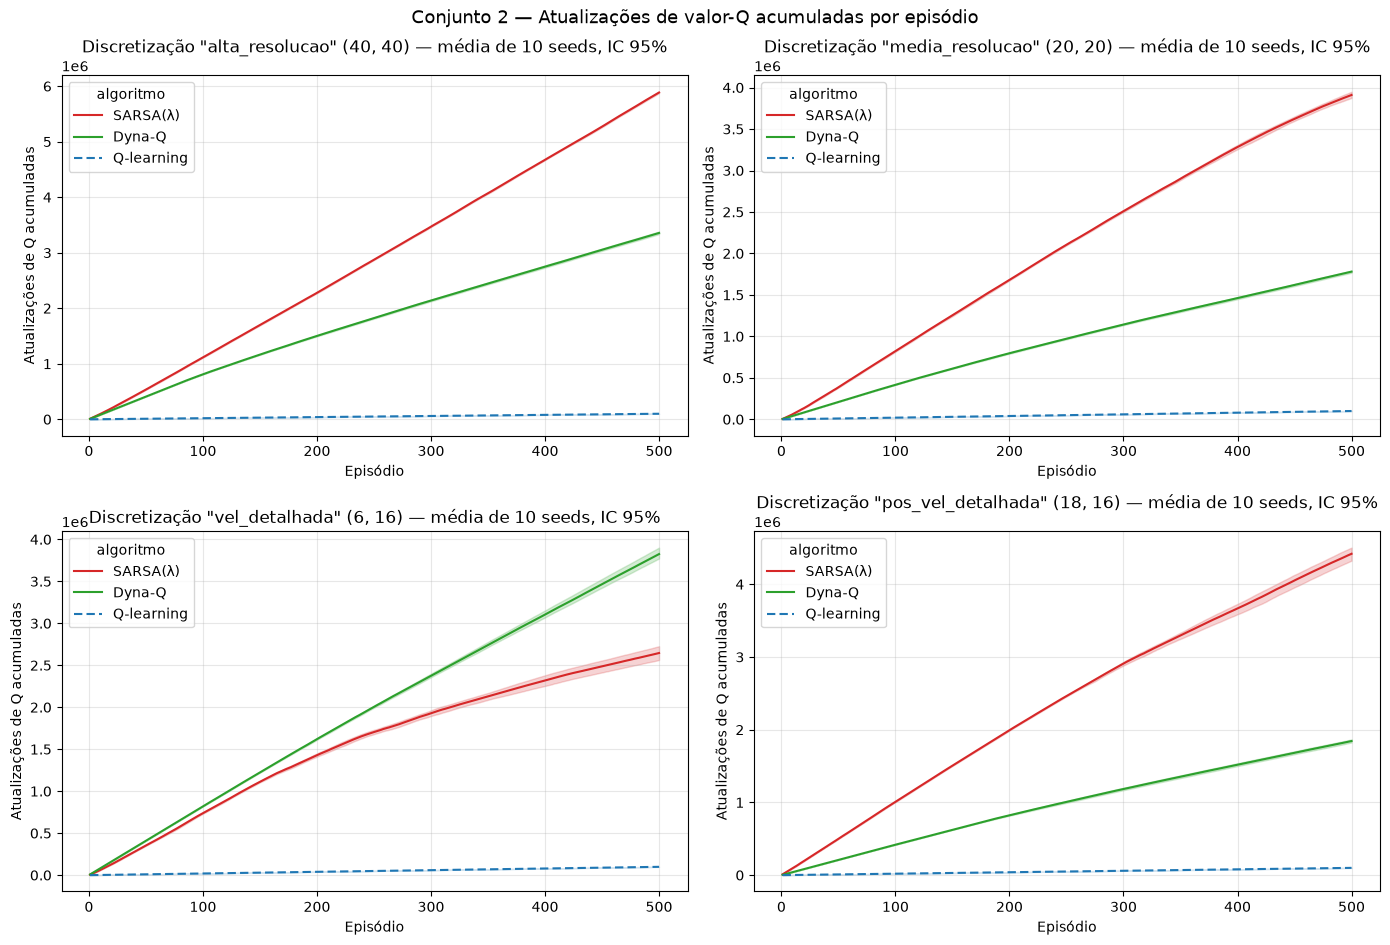

In [7]:
# ==============================================================================
# GRÁFICOS
# ==============================================================================
# Curva principal = média entre seeds; área sombreada = IC de 95%.
#   metodo_ic='bootstrap' -> seaborn.lineplot(errorbar=('ci', 95)) (bootstrap da média entre seeds)
#   metodo_ic='t'         -> média ± t_{0.975, n-1} · s/√n, calculado manualmente
# `suavizacao` > 1 aplica média móvel (por seed, antes de agregar) — escolha do aluno;
# o padrão 1 mostra os dados brutos.

CORES = {'Q-learning': '#1f77b4', 'SARSA(λ)': '#d62728', 'Dyna-Q': '#2ca02c'}
# Q-learning tracejado e desenhado por último (por cima): quando fica em 200 junto com outro
# algoritmo, as duas curvas continuam visíveis.
TRACEJADOS = {'Q-learning': (4, 2), 'SARSA(λ)': '', 'Dyna-Q': ''}
ORDEM_DESENHO = ['SARSA(λ)', 'Dyna-Q', 'Q-learning']
PASTA_FIGURAS = os.path.join(PASTA_RESULTADOS, 'figuras')
os.makedirs(PASTA_FIGURAS, exist_ok=True)


def _grade_de_eixos(n, largura=7, altura=4.8, colunas=2):
    """Figura com n subplots em até `colunas` colunas; esconde os eixos que sobrarem."""
    ncols = min(colunas, n)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(largura * ncols, altura * nrows), squeeze=False)
    axes = axes.ravel()
    for ax in axes[n:]:
        ax.set_visible(False)
    return fig, axes[:n]


def _suavizar(df, y, janela, grupo=('rotulo', 'seed')):
    if janela <= 1:
        return df
    df = df.copy()
    df[y] = df.groupby(list(grupo), sort=False)[y].transform(
        lambda v: v.rolling(janela, min_periods=1).mean())
    return df


def plotar_curvas(df, y, ax, x='episodio', hue='algoritmo', metodo_ic='bootstrap',
                  suavizacao=1, escala_log=False, titulo=None, rotulo_y=None, paleta=None):
    """Desenha, num eixo, uma curva (média + IC 95% sombreado) por valor de `hue`."""
    d = _suavizar(df, y, suavizacao, grupo=(hue, 'seed'))
    paleta = paleta if paleta is not None else (CORES if hue == 'algoritmo' else None)
    if metodo_ic == 'bootstrap':
        estilo = {}
        if hue == 'algoritmo':
            presentes = set(d[hue])
            estilo = dict(hue_order=[a for a in ORDEM_DESENHO if a in presentes], style=hue,
                          dashes={a: TRACEJADOS[a] for a in presentes})
        sns.lineplot(data=d, x=x, y=y, hue=hue, errorbar=('ci', 95), n_boot=1000, seed=0,
                     palette=paleta, ax=ax, **estilo)
    elif metodo_ic == 't':
        grupos = dict(list(d.groupby(hue, sort=False)))
        if hue == 'algoritmo':
            grupos = {a: grupos[a] for a in ORDEM_DESENHO if a in grupos}
        for i, (nome, g) in enumerate(grupos.items()):
            agg = g.groupby(x)[y].agg(['mean', 'std', 'count'])
            t = np.array([quantil_t(n - 1) if n > 1 else np.nan for n in agg['count']])
            meia = t * agg['std'] / np.sqrt(agg['count'])
            cor = paleta.get(nome) if isinstance(paleta, dict) else f'C{i}'
            ax.plot(agg.index, agg['mean'], label=nome, color=cor,
                    ls='--' if nome == 'Q-learning' else '-')
            ax.fill_between(agg.index, agg['mean'] - meia, agg['mean'] + meia, color=cor, alpha=0.2)
        ax.legend(title=hue)
    else:
        raise ValueError("metodo_ic deve ser 'bootstrap' ou 't'")
    if escala_log:
        ax.set_yscale('log')
    ax.set_xlabel('Episódio' if x == 'episodio' else x)
    ax.set_ylabel(rotulo_y or y)
    if titulo:
        ax.set_title(titulo)
    ax.grid(alpha=0.3)
    return ax


def plotar_conjunto(df, y, rotulo_y, titulo, nome_arquivo=None, **kwargs):
    """Um subplot por discretização, com os 3 algoritmos em cada um."""
    discs = list(dict.fromkeys(df['discretizacao']))
    fig, axes = _grade_de_eixos(len(discs))
    for ax, nome_disc in zip(axes, discs):
        bins = DISCRETIZADORES[nome_disc].bins if nome_disc in DISCRETIZADORES else ''
        n_seeds = df.loc[df.discretizacao == nome_disc, 'seed'].nunique()
        plotar_curvas(df[df.discretizacao == nome_disc], y, ax, rotulo_y=rotulo_y,
                      titulo=f'Discretização "{nome_disc}" {bins} — média de {n_seeds} seeds, IC 95%',
                      **kwargs)
    fig.suptitle(titulo, fontsize=13)
    fig.tight_layout()
    if nome_arquivo:
        fig.savefig(os.path.join(PASTA_FIGURAS, nome_arquivo), dpi=150, bbox_inches='tight')
    plt.show()
    return fig


# --- Conjunto 1: episódios (x) vs. passos até o sucesso (y) ----------------------
# Episódios que não chegam ao objetivo são truncados em MAX_PASSOS_EPISODIO passos
# (esse valor aparece como teto no gráfico).
fig_passos = plotar_conjunto(
    resultados, y='passos', rotulo_y='Passos até o sucesso (no episódio)',
    titulo='Conjunto 1 — Passos até o sucesso por episódio',
    nome_arquivo='conjunto1_passos_por_episodio.png', metodo_ic='bootstrap', suavizacao=1)

# --- Conjunto 2: episódios (x) vs. nº de atualizações de valor-Q (y) ------------------
# Aqui: atualizações ACUMULADAS desde o início do treino (custo computacional total).
# Para ver o custo por episódio, use y='atualizacoes_q_episodio'. Use escala_log=True se
# as curvas tiverem ordens de grandeza muito diferentes.
fig_atualiz = plotar_conjunto(
    resultados, y='atualizacoes_q_acumuladas', rotulo_y='Atualizações de Q acumuladas',
    titulo='Conjunto 2 — Atualizações de valor-Q acumuladas por episódio',
    nome_arquivo='conjunto2_atualizacoes_q.png', metodo_ic='bootstrap', escala_log=False)

### Apoio à análise (tabelas e gráficos complementares)

Tabela-resumo por configuração (média entre seeds ± IC 95%), recompensa vs. passos acumulados no ambiente e estatísticas do modelo aprendido pelo Dyna-Q (para a questão sobre *aliasing*). Esta célula apenas mede; a interpretação fica para a seção 4.2.

,discretizacao,algoritmo,rotulo,n_seeds,episodios,passos_medios_todos,passos_medios_todos_ic95,passos_medios_ult50,passos_medios_ult50_ic95,taxa_sucesso_ult50,taxa_sucesso_ult50_ic95,primeiro_sucesso_ep,primeiro_sucesso_ep_ic95,passos_ambiente_total,passos_ambiente_total_ic95,atualizacoes_q_total,atualizacoes_q_total_ic95,atualiz_q_por_passo,atualiz_q_por_passo_ic95,tempo_s,tempo_s_ic95
0,alta_resolucao,Q-learning,Q-learning,10,500,200,0,200,0,0,0,NaN,NaN,1e+05,0,1e+05,0,1,0,6.42,0.459
1,alta_resolucao,SARSA(λ),SARSA(λ),10,500,200,0,200,0,0,0,NaN,NaN,1e+05,0,5.89e+06,1.55e+04,58.9,0.155,12.4,0.224
2,alta_resolucao,Dyna-Q,Dyna-Q,10,500,164,1.41,148,3.03,0.988,0.0121,83,4.96,8.19e+04,705,3.36e+06,2.89e+04,41,0,47.4,2.52
3,media_resolucao,Q-learning,Q-learning,10,500,200,0.0297,200,0.283,0.012,0.0138,439,16.6,1e+05,14.9,1e+05,14.9,1,0,8.79,0.446
4,media_resolucao,SARSA(λ),SARSA(λ),10,500,193,1.31,167,10.5,0.802,0.153,218,20.3,9.67e+04,654,3.91e+06,4.57e+04,40.5,0.271,8.94,0.265
5,media_resolucao,Dyna-Q,Dyna-Q,10,500,170,1.48,153,2.79,0.972,0.0168,81.9,10.3,8.48e+04,739,1.78e+06,1.55e+04,21,0,39.3,4.88
6,vel_detalhada,Q-learning,Q-learning,10,500,198,0.609,198,2.1,0.064,0.0543,222,32.3,9.9e+04,304,9.9e+04,304,1,0,10.6,0.873
7,vel_detalhada,SARSA(λ),SARSA(λ),10,500,168,2.52,138,5.49,0.968,0.0532,112,20.1,8.4e+04,1.26e+03,2.65e+06,1.02e+05,31.5,0.956,9.19,0.241
8,vel_detalhada,Dyna-Q,Dyna-Q,10,500,187,3.81,175,7.78,0.568,0.165,110,23.3,9.33e+04,1.91e+03,3.82e+06,7.81e+04,41,0,47.1,1.46
9,pos_vel_detalhada,Q-learning,Q-learning,10,500,200,0.0361,200,0.385,0.016,0.0232,431,43.4,1e+05,18,1e+05,18,1,0,10.9,0.955


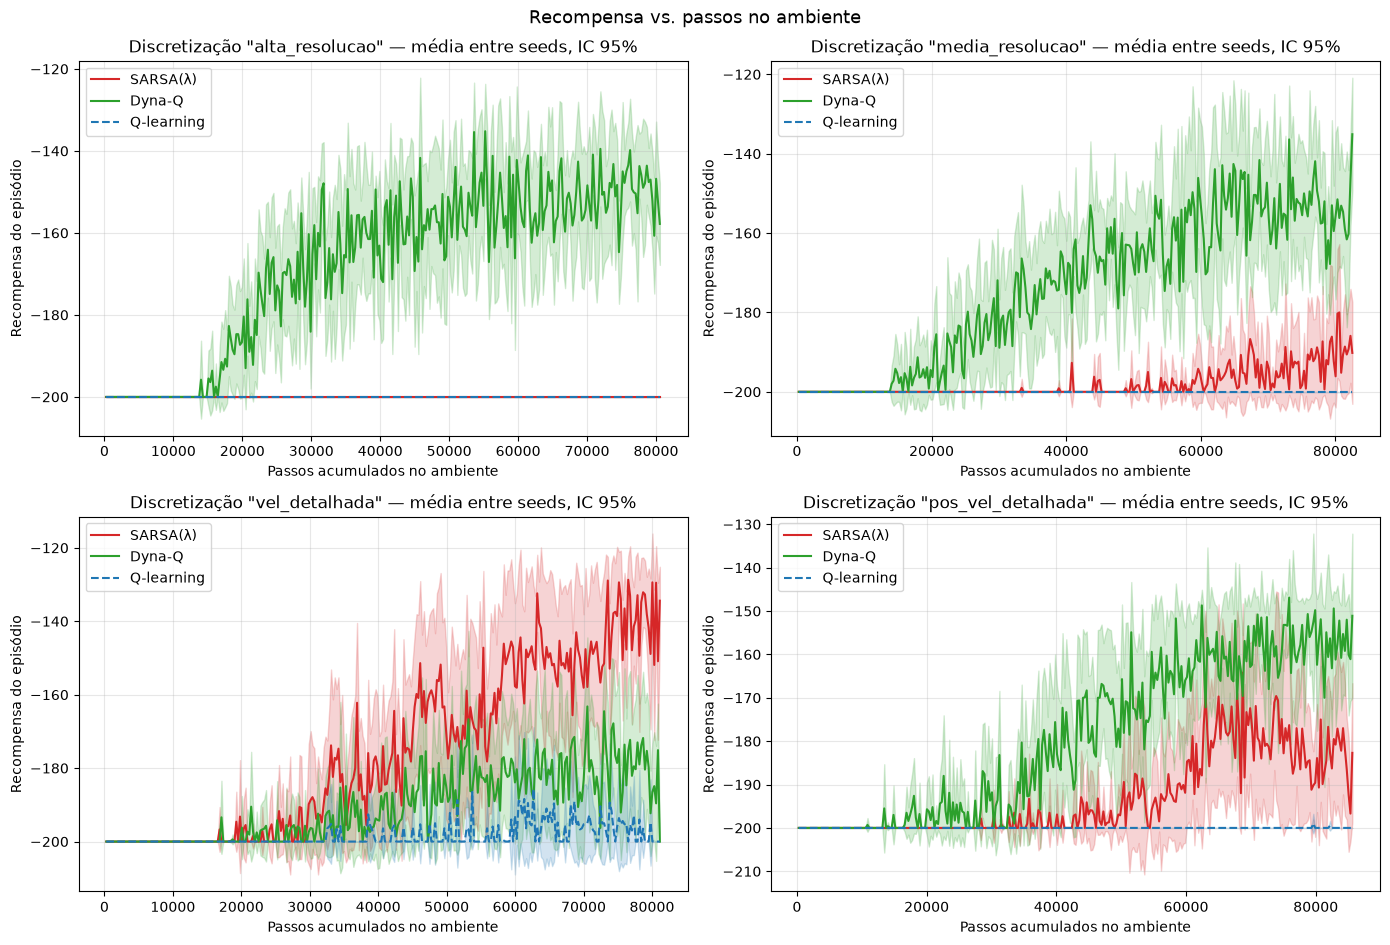

,,pares_observados,frac_tabela_observada,transicoes_registradas,frac_pares_nao_deterministicos,media_desfechos_distintos_por_par,max_desfechos_distintos_por_par,entropia_media_bits,entropia_media_ponderada_bits,frac_transicoes_para_mesmo_estado,pares_terminal_ambiguo
discretizacao,algoritmo,,,,,,,,,,
alta_resolucao,Dyna-Q,3.31e+03,0.69,8.19e+04,0.824,2.68,6,1.03,1.28,0.266,21.5
media_resolucao,Dyna-Q,815,0.679,8.48e+04,0.959,3.43,6,1.29,1.28,0.586,10
vel_detalhada,Dyna-Q,263,0.912,9.33e+04,0.969,3.34,5.5,0.96,1,0.663,9.2
pos_vel_detalhada,Dyna-Q,712,0.824,8.78e+04,0.947,3.1,5.8,1.03,1.13,0.543,8.4


In [8]:
# ==============================================================================
# APOIO À ANÁLISE (opcional): tabelas-resumo, recompensa vs. passos no ambiente e
# estatísticas do modelo do Dyna-Q (aliasing). Apenas MEDE; a interpretação é do aluno.
# ==============================================================================

# (1) Tabela-resumo: média entre seeds e meia-largura do IC 95% (colunas *_ic95)
ULTIMOS = 50   # janela de episódios finais usada nas métricas "ult"
resumo = tabela_resumo(resultados, ultimos=ULTIMOS)
resumo.to_csv(os.path.join(PASTA_RESULTADOS, 'resumo.csv'), index=False)
with pd.option_context('display.float_format', '{:,.3g}'.format, 'display.max_columns', 50):
    display(resumo)


# (2) Recompensa do episódio vs. passos acumulados no ambiente (eixo x = amostras usadas).
#     Cada seed é reamostrada numa grade comum de passos (valor = recompensa do episódio em
#     andamento naquele passo); depois, média ± IC 95% (t) entre seeds.
def plotar_recompensa_vs_passos(df, n_pontos=300, conf=0.95, nome_arquivo=None):
    discs = list(dict.fromkeys(df['discretizacao']))
    fig, axes = _grade_de_eixos(len(discs))
    for ax, nome_disc in zip(axes, discs):
        dd = df[df.discretizacao == nome_disc]
        x_max = dd.groupby(['algoritmo', 'seed']).passos_acumulados.max().min()
        grade = np.linspace(0, x_max, n_pontos)[1:]
        grupos = dict(list(dd.groupby('algoritmo', sort=False)))
        for nome_alg in [a for a in ORDEM_DESENHO if a in grupos]:
            g = grupos[nome_alg]
            curvas = []
            for _, gs in g.groupby('seed'):
                fim = gs.passos_acumulados.to_numpy()
                idx = np.searchsorted(fim, grade, side='left')   # episódio que contém o passo
                curvas.append(gs.recompensa.to_numpy()[np.minimum(idx, len(fim) - 1)])
            curvas = np.array(curvas)
            m = curvas.mean(axis=0)
            n = curvas.shape[0]
            h = quantil_t(n - 1, conf) * curvas.std(axis=0, ddof=1) / np.sqrt(n) if n > 1 else 0 * m
            cor = CORES.get(nome_alg)
            ax.plot(grade, m, label=nome_alg, color=cor, ls='--' if nome_alg == 'Q-learning' else '-')
            ax.fill_between(grade, m - h, m + h, color=cor, alpha=0.2)
        ax.set_xlabel('Passos acumulados no ambiente')
        ax.set_ylabel('Recompensa do episódio')
        ax.set_title(f'Discretização "{nome_disc}" — média entre seeds, IC 95%')
        ax.grid(alpha=0.3)
        ax.legend()
    fig.suptitle('Recompensa vs. passos no ambiente', fontsize=13)
    fig.tight_layout()
    if nome_arquivo:
        fig.savefig(os.path.join(PASTA_FIGURAS, nome_arquivo), dpi=150, bbox_inches='tight')
    plt.show()
    return fig


fig_recompensa = plotar_recompensa_vs_passos(resultados, nome_arquivo='recompensa_vs_passos.png')


# (3) Estatísticas do modelo aprendido pelo Dyna-Q (por discretização, média entre seeds).
#     - frac_pares_nao_deterministicos: fração dos (s,a) observados que levaram a mais de um s'
#     - entropia_media_*: entropia (bits) da distribuição empírica de desfechos por (s,a)
#     - frac_transicoes_para_mesmo_estado: fração das transições com s' == s
#     - pares_terminal_ambiguo: nº de (s,a) que às vezes terminaram o episódio e às vezes não
def tabela_modelo_dyna(pacotes):
    linhas = []
    for (nome_disc, nome_alg), pac in pacotes.items():
        for seed, est in pac['extras'].items():
            if est:
                linhas.append({'discretizacao': nome_disc, 'algoritmo': nome_alg, 'seed': seed, **est})
    if not linhas:
        return pd.DataFrame()
    return pd.DataFrame(linhas).drop(columns='seed').groupby(['discretizacao', 'algoritmo'], sort=False).mean()


with pd.option_context('display.float_format', '{:,.3g}'.format):
    display(tabela_modelo_dyna(PACOTES))

## 4.2 Análise de Resultados e Aliasing de Estados

*(Respondam de forma dissertativa, embasando-se nos gráficos gerados acima)*

### a) Qual o melhor algoritmo em termos de eficiência amostral?
_(A ser escrito pelo aluno)_

### b) Qual o melhor algoritmo em termos de eficiência computacional?
_(A ser escrito pelo aluno)_

### c) Como a modelagem de estados afetou especificamente o modelo construído pelo Dyna-Q em comparação com o SARSA(λ)? Pense na relação entre as transições reais do ambiente vs nos estados discretizados.
_(A ser escrito pelo aluno)_

In [9]:
# ==============================================================================
# GRAVAÇÃO E EXIBIÇÃO DE VÍDEO DOS AGENTES TREINADOS
# ==============================================================================
# Salve um ou mais episódios dos seus agentes que valem a pena serem vistos
#
# A gravação usa a tabela Q FINAL salva em PACOTES (não é preciso re-treinar) e executa a
# política GULOSA (epsilon = 0). O vídeo (.mp4) é gerado pelo wrapper RecordVideo e exibido
# embutido no notebook (HTML5 + base64), o que funciona tanto no Colab quanto localmente.

PASTA_VIDEOS = os.path.join(PASTA_RESULTADOS, 'videos')


def politica_gulosa(q_values):
    """Política gulosa a partir de uma tabela Q (desempate: primeira ação de maior valor)."""
    return lambda s: int(np.argmax(q_values[s]))


def gravar_video(q_values, discretizacao, prefixo='agente', seed_ambiente=0,
                 max_passos_episodio=None, pasta=None):
    """Grava UM episódio da política gulosa. Devolve (caminho_mp4, passos, sucesso)."""
    disc = _obter_discretizador(discretizacao)
    max_passos_episodio = MAX_PASSOS_EPISODIO if max_passos_episodio is None else max_passos_episodio
    pasta = PASTA_VIDEOS if pasta is None else pasta
    os.makedirs(pasta, exist_ok=True)
    prefixo = _slug(prefixo)
    for antigo in glob.glob(os.path.join(pasta, f'{prefixo}-episode-*.mp4')):
        os.remove(antigo)   # evita exibir um vídeo antigo com o mesmo nome

    env = criar_ambiente(max_passos_episodio, render_mode='rgb_array')
    env = RecordVideo(env, video_folder=pasta, name_prefix=prefixo,
                      episode_trigger=lambda ep: True, disable_logger=True)
    pi = politica_gulosa(q_values)
    obs, _ = env.reset(seed=seed_ambiente)
    passos, terminou, truncou = 0, False, False
    while not (terminou or truncou):
        obs, r, terminou, truncou, _ = env.step(pi(disc(obs)))
        passos += 1
    env.close()   # fecha e grava o arquivo
    arquivos = sorted(glob.glob(os.path.join(pasta, f'{prefixo}-episode-*.mp4')), key=os.path.getmtime)
    if not arquivos:
        raise RuntimeError('Nenhum vídeo gerado (verifique se moviepy e pygame estão instalados).')
    return arquivos[-1], passos, bool(terminou)


def mostrar_video(caminho, largura=480):
    """Exibe um .mp4 embutido no notebook (Colab ou Jupyter local)."""
    with open(caminho, 'rb') as f:
        dados = base64.b64encode(f.read()).decode('ascii')
    return HTML(f'<video width="{largura}" controls loop autoplay muted>'
                f'<source src="data:video/mp4;base64,{dados}" type="video/mp4"></video>')


def selecionar_seed(df, nome_disc, nome_alg, criterio='melhor', ultimos=50):
    """Seed com menor ('melhor') ou maior ('pior') média de passos nos últimos episódios."""
    d = df[(df.discretizacao == nome_disc) & (df.algoritmo == nome_alg)]
    medias = d.groupby('seed').apply(lambda g: g.passos.tail(ultimos).mean(), include_groups=False)
    return int(medias.idxmin() if criterio == 'melhor' else medias.idxmax())


# --- Exemplo de uso: o ALUNO escolhe quais agentes/seeds vale a pena mostrar ------------
# (aqui: a seed com melhor desempenho final de cada algoritmo, em cada discretização)
SEED_AMBIENTE_VIDEO = 2024   # estado inicial do episódio gravado (escolha livre)
for nome_disc in DISCRETIZACOES:
    for nome_alg in ALGORITMOS:
        seed = selecionar_seed(resultados, nome_disc, nome_alg, criterio='melhor')
        q = PACOTES[(nome_disc, nome_alg)]['q_tables'][seed]
        caminho, passos, sucesso = gravar_video(q, nome_disc, prefixo=f'{nome_disc}_{nome_alg}_seed{seed}',
                                                seed_ambiente=SEED_AMBIENTE_VIDEO)
        print(f'{nome_disc} | {nome_alg} | seed de treino {seed}: {passos} passos, '
              f'{"sucesso" if sucesso else "não chegou ao topo"} -> {caminho}')
        display(mostrar_video(caminho))

alta_resolucao | Q-learning | seed de treino 0: 200 passos, não chegou ao topo -> resultados\videos\alta_resolucao_Q-learning_seed0-episode-0.mp4


alta_resolucao | SARSA(λ) | seed de treino 0: 200 passos, não chegou ao topo -> resultados\videos\alta_resolucao_SARSA_lambda__seed0-episode-0.mp4


alta_resolucao | Dyna-Q | seed de treino 7: 153 passos, sucesso -> resultados\videos\alta_resolucao_Dyna-Q_seed7-episode-0.mp4


media_resolucao | Q-learning | seed de treino 4: 200 passos, não chegou ao topo -> resultados\videos\media_resolucao_Q-learning_seed4-episode-0.mp4


media_resolucao | SARSA(λ) | seed de treino 9: 151 passos, sucesso -> resultados\videos\media_resolucao_SARSA_lambda__seed9-episode-0.mp4


...

vel_detalhada | SARSA(λ) | seed de treino 6: 122 passos, sucesso -> resultados\videos\vel_detalhada_SARSA_lambda__seed6-episode-0.mp4


vel_detalhada | Dyna-Q | seed de treino 6: 200 passos, não chegou ao topo -> resultados\videos\vel_detalhada_Dyna-Q_seed6-episode-0.mp4


pos_vel_detalhada | Q-learning | seed de treino 5: 162 passos, sucesso -> resultados\videos\pos_vel_detalhada_Q-learning_seed5-episode-0.mp4


pos_vel_detalhada | SARSA(λ) | seed de treino 6: 200 passos, não chegou ao topo -> resultados\videos\pos_vel_detalhada_SARSA_lambda__seed6-episode-0.mp4


pos_vel_detalhada | Dyna-Q | seed de treino 8: 149 passos, sucesso -> resultados\videos\pos_vel_detalhada_Dyna-Q_seed8-episode-0.mp4


### d) Vídeos: quais agentes valem a pena ser vistos e por quê? (melhor desempenho, política inusitada, etc.)
_(A ser escrito pelo aluno)_

## 4.3 Diário de Bordo e Registro de Falhas


### a) O que notadamente falhou nas escolhas de hiperparâmetros (alpha, decaimento de epsilon, λ, N)? Por que falharam?
_(A ser escrito pelo aluno)_

### b) Houve alguma dificuldade ou erros na implementação de alguma etapa do projeto? Como foi resolvido?
_(A ser escrito pelo aluno)_

### c) O que mais vale a pena relatar que não foi coberto nas demais perguntas?
_(A ser escrito pelo aluno)_

## Apêndice (opcional): busca de hiperparâmetros

Ferramenta para conduzir a busca da "melhor parametrização" (Tarefa C): `gerar_grade(...)` monta a lista de configurações e `busca_hiperparametros(...)` roda cada uma com várias seeds, salva em disco e devolve uma tabela-resumo. Desligada por padrão (`EXECUTAR_BUSCA = False`).

*Obs.: o enunciado do Colab pede que fique aqui apenas o código da parametrização final; esta seção pode ser movida para outro notebook e referenciada no diário de bordo.*

In [10]:
# ==============================================================================
# APÊNDICE: BUSCA DE HIPERPARÂMETROS (desligada por padrão)
# ==============================================================================
# Mude EXECUTAR_BUSCA para True para rodar. A grade abaixo é só um EXEMPLO de como usar
# as funções — quais parâmetros variar, quais valores testar e qual métrica usar para
# escolher a "melhor parametrização" são decisões do aluno.
EXECUTAR_BUSCA = False

if EXECUTAR_BUSCA:
    nome_disc_busca, nome_alg_busca = list(DISCRETIZACOES)[0], 'Dyna-Q'          # EXEMPLO
    grade = gerar_grade(HIPERPARAMETROS[nome_disc_busca][nome_alg_busca],         # EXEMPLO
                        n_planejamento=[5, 20], alpha=[0.1, 0.3])
    resumo_busca, episodios_busca = busca_hiperparametros(
        nome_alg_busca, nome_disc_busca, grade,
        seeds=SEEDS,               # pode usar menos seeds na busca e 10+ só na configuração final
        n_episodios=N_EPISODIOS)
    with pd.option_context('display.float_format', '{:,.3g}'.format, 'display.max_columns', 50):
        display(resumo_busca)

    # Curvas de todas as configurações testadas (uma cor por configuração)
    fig, ax = plt.subplots(figsize=(9, 5))
    plotar_curvas(episodios_busca, 'passos', ax, hue='rotulo', metodo_ic='t',
                  rotulo_y='Passos até o sucesso',
                  titulo=f'Busca: {nome_alg_busca} — discretização "{nome_disc_busca}"')
    plt.show()